In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


#### imports

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score

In [3]:

train_df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")

### Ordinal features and non-ordinal features:

+ I want to write a corruption pipeline which tests the features individually, collectively and as subsets.

+ I want to segregate the type based on the information they capture and their type.

+ It made sense to sort this way as I presumed we would be handling data corruption differently for ordinal features (0-5 or 1-5) and non-ordinal features(numeric or categorical)

In [4]:
ordinal_candidates = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
]

ordinal_features = [
    col for col in ordinal_candidates
    if col in train_df.columns
]

non_ord_features = [
    col for col in train_df.columns
    if col not in ordinal_candidates
]

# Printing out the captured data for each

print("Ordinal features found:", len(ordinal_features))
print(ordinal_features)

for col in ordinal_features:
    print(f"\n{col}")
    print(sorted(train_df[col].dropna().unique().tolist()))

print("\nNon-ordinal features found:", len(non_ord_features))
print(non_ord_features)

non_ord_list = list()

for col in non_ord_features:
    print(f"\n{col}")
    print(f"\nLength of unique feature values: {len(train_df[col].dropna().unique().tolist())}")
    elem_set = set((train_df[col].dropna().unique().tolist()))
    non_ord_list.append(elem_set)
    print((train_df[col].dropna().unique().tolist())[:10])

Ordinal features found: 13
['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']

Inflight wifi service
[0, 1, 2, 3, 4, 5]

Departure/Arrival time convenient
[0, 1, 2, 3, 4, 5]

Ease of Online booking
[0, 1, 2, 3, 4, 5]

Gate location
[0, 1, 2, 3, 4, 5]

Food and drink
[0, 1, 2, 3, 4, 5]

Online boarding
[0, 1, 2, 3, 4, 5]

Seat comfort
[0, 1, 2, 3, 4, 5]

Inflight entertainment
[0, 1, 2, 3, 4, 5]

On-board service
[0, 1, 2, 3, 4, 5]

Leg room service
[0, 1, 2, 3, 4, 5]

Baggage handling
[1, 2, 3, 4, 5]

Checkin service
[0, 1, 2, 3, 4, 5]

Cleanliness
[0, 1, 2, 3, 4, 5]

Non-ordinal features found: 10
['id', 'Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

id



### Removing target columns and any ID-like columns from dataset to produce 'X' - a strict feature set

In [5]:
from sklearn.model_selection import train_test_split

TARGET = "satisfaction"

# Remove the target and any ID-like columns from predictors.
id_columns = [
    col for col in train_df.columns
    if col.strip().lower() in {"id", "passengerid", "passenger_id"}
]

feature_columns = [
    col for col in train_df.columns
    if col != TARGET and col not in id_columns
]

X_original = train_df[feature_columns].copy()
y = train_df[TARGET].copy()

print("Feature matrix:", X_original.shape)
print("Target:", y.shape)
print("ID columns excluded:", id_columns)
print("Target classes:", y.unique())

categorical_features = X_original.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Ordinal features must be treated as numeric for this experiment.
for col in ordinal_features:
    if col in categorical_features:
        categorical_features.remove(col)
    if col not in numerical_features:
        numerical_features.append(col)

Feature matrix: (699635, 21)
Target: (699635,)
ID columns excluded: ['id']
Target classes: [False  True]


In [6]:
# Encode the target as 0 and 1.
target_encoder = LabelEncoder()
y = pd.Series(
    target_encoder.fit_transform(train_df[TARGET]),
    index=train_df.index,
    name=TARGET
)

print("Target mapping:")
print(dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))

# Exclude target and identifier columns.
id_columns = [
    col for col in train_df.columns
    if col.strip().lower() in {"id", "passengerid", "passenger_id"}
]

feature_columns = [
    col for col in train_df.columns
    if col != TARGET and col not in id_columns
]

# Infer categorical and numerical columns.
categorical_features = [
    col for col in feature_columns
    if (
        pd.api.types.is_object_dtype(train_df[col])
        or isinstance(train_df[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(train_df[col])
    )
]

numeric_features = [
    col for col in feature_columns
    if col not in categorical_features
]

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Target mapping:
{np.False_: np.int64(0), np.True_: np.int64(1)}
Numeric features: 17
Categorical features: 4


### Producing different seeds of the same dataset -  to ensure the output is trained/tested/validated on differing data

In [7]:
from sklearn.model_selection import train_test_split

SPLIT_SEEDS = [42, 123, 2025, 7, 99]

splits = []

for seed in SPLIT_SEEDS:
    # First separate the test portion.
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X_original,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    # Then separate validation from training.
    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train_val,
        y_train_val,
        test_size=0.20,
        random_state=seed + 1,
        stratify=y_train_val
    )

    splits.append({
        "seed": seed,
        "train_idx": X_train.index,
        "valid_idx": X_valid.index,
        "test_idx": X_test.index
    })

    print(
        f"Seed {seed}: "
        f"train={len(X_train)}, "
        f"validation={len(X_valid)}, "
        f"test={len(X_test)}"
    )

Seed 42: train=447766, validation=111942, test=139927
Seed 123: train=447766, validation=111942, test=139927
Seed 2025: train=447766, validation=111942, test=139927
Seed 7: train=447766, validation=111942, test=139927
Seed 99: train=447766, validation=111942, test=139927


### Creating a pipeline for a decision tree and random forest classifier

In [8]:
def build_pipeline(model_name, max_d=None, n_est=100, seed=42):

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocess = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])

    if model_name == "Majority baseline":
        model = DummyClassifier(strategy="most_frequent")

    elif model_name == "Decision tree":
        model = DecisionTreeClassifier(
            max_depth=max_d, min_samples_leaf=20, random_state=seed
        )

    elif model_name == "Random forest":
        model = RandomForestClassifier(
            n_estimators=n_est,
            max_depth=max_d,
            min_samples_leaf=10,
            max_features="sqrt",
            n_jobs=-1,
            random_state=seed,
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return Pipeline([("preprocess", preprocess), ("model", model)])


model_names = ["Majority baseline", "Decision tree", "Random forest"]

print("Models:", model_names)


Models: ['Majority baseline', 'Decision tree', 'Random forest']


## Data corruption code - Based on Rajavel's

"""
def corrupt_ordinal_features(X, rate, seed, features):
    Replace selected ordinal ratings in a list of features with

    different randomly chosen values from 0, 1, 2, 3, 4, 5.

    Only the specified features are modified.
    
    rng = np.random.default_rng(seed)

    X_corrupted = X.copy()

    for feature in features:
        if feature not in X_corrupted.columns:
            raise ValueError(
                f"Feature '{feature}' not found.\n"
                f"Available columns: {X_corrupted.columns.tolist()}"
            )

        n = len(X_corrupted)
        n_corrupt = int(round(rate * n))

        indices = rng.choice(n, size=n_corrupt, replace=False)
        original_values = X_corrupted[feature].to_numpy().copy()

        new_values = rng.integers(low=0, high=6, size=n_corrupt)      
        old_values = original_values[indices]

        new_values = np.where(
            new_values == old_values, (new_values + 1) % 6, new_values
        )

        # Replace values at the selected positions.
        X_corrupted.iloc[indices, X_corrupted.columns.get_loc(feature)] = (
            new_values
        )

    return X_corrupted
"""

## Trying to find optimal depth and number of learners

DT max_d: 3 | RF n_est: 50 || DT ROC-AUC: 0.90789, F1: 0.86099 | RF ROC-AUC: 0.95688, F1: 0.91379
DT max_d: 5 | RF n_est: 100 || DT ROC-AUC: 0.93652, F1: 0.87446 | RF ROC-AUC: 0.9571, F1: 0.91421
DT max_d: 8 | RF n_est: 150 || DT ROC-AUC: 0.94931, F1: 0.89456 | RF ROC-AUC: 0.95722, F1: 0.9141
DT max_d: 10 | RF n_est: 200 || DT ROC-AUC: 0.95257, F1: 0.90443 | RF ROC-AUC: 0.9572, F1: 0.91404
DT max_d: 15 | RF n_est: 300 || DT ROC-AUC: 0.95207, F1: 0.9098 | RF ROC-AUC: 0.95723, F1: 0.9142
DT max_d: 20 | RF n_est: 400 || DT ROC-AUC: 0.95006, F1: 0.90924 | RF ROC-AUC: 0.95725, F1: 0.91417
DT max_d: None | RF n_est: 500 || DT ROC-AUC: 0.94819, F1: 0.90899 | RF ROC-AUC: 0.95728, F1: 0.91423


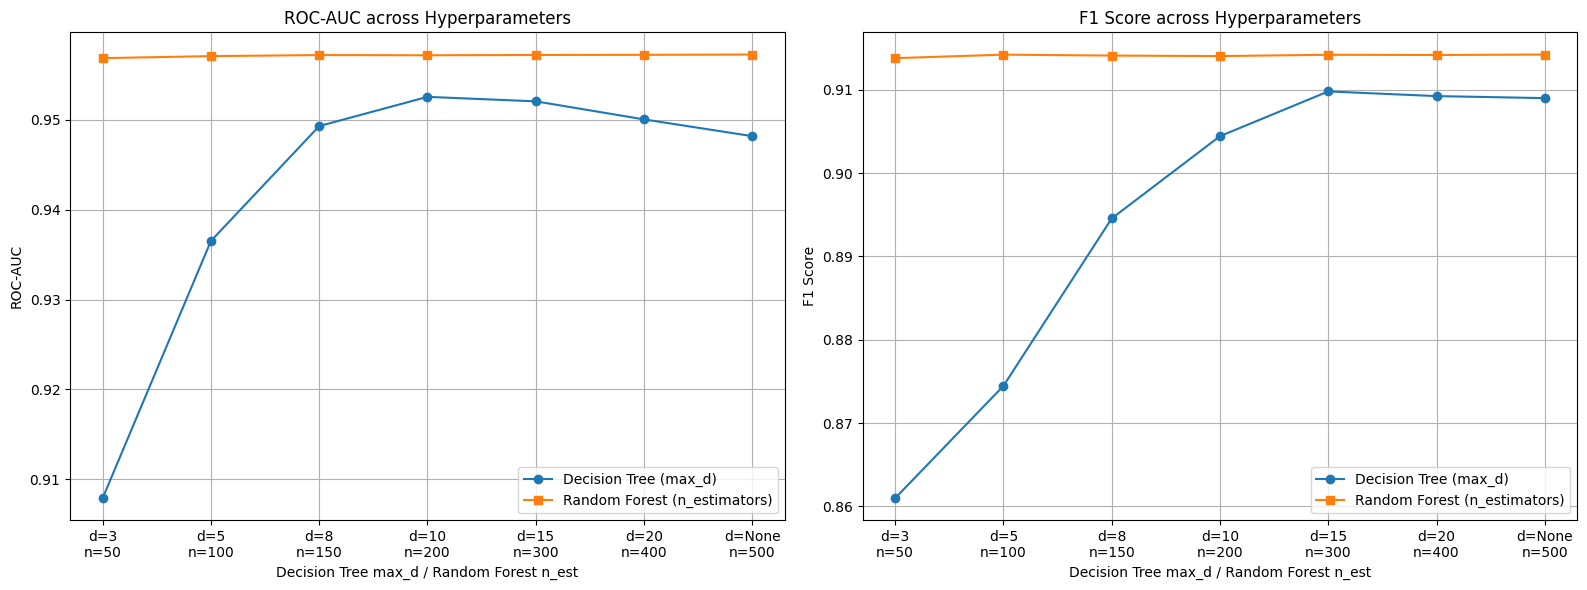

In [9]:
depths = [3, 5, 8, 10, 15, 20, None]
n_estimators_list = [50, 100, 150, 200, 300, 400, 500]

dt_roc_scores = []
dt_f1_scores = []
rf_roc_scores = []
rf_f1_scores = []

# Using X_train and X_test / y_test as requested
X_pilot_train = X_train[feature_columns]
y_pilot_train = y_train

X_pilot_test = X_test[feature_columns]
y_pilot_test = y_test

# Assuming a default seed for pipeline building
seed_val = 42

for max_d_val, n_est_val in zip(depths, n_estimators_list):
  # Evaluate Decision Tree (varying max_d)
  dt_model = build_pipeline("Decision tree", seed=seed_val, max_d=max_d_val)
  dt_model.fit(X_pilot_train, y_pilot_train)
  dt_prob = dt_model.predict_proba(X_pilot_test)[:, 1]
  dt_pred = (dt_prob >= 0.5).astype(int)

  dt_roc = roc_auc_score(y_pilot_test, dt_prob)
  dt_f1 = f1_score(y_pilot_test, dt_pred)
  dt_roc_scores.append(dt_roc)
  dt_f1_scores.append(dt_f1)

  # Evaluate Random Forest (varying n_est, with max_d fixed or tuned independently if desired)
  rf_model = build_pipeline(
      "Random forest", seed=seed_val, max_d=20, n_est=n_est_val
  )
  rf_model.fit(X_pilot_train, y_pilot_train)
  rf_prob = rf_model.predict_proba(X_pilot_test)[:, 1]
  rf_pred = (rf_prob >= 0.5).astype(int)

  rf_roc = roc_auc_score(y_pilot_test, rf_prob)
  rf_f1 = f1_score(y_pilot_test, rf_pred)
  rf_roc_scores.append(rf_roc)
  rf_f1_scores.append(rf_f1)

  print(
      f"DT max_d: {max_d_val} | RF n_est: {n_est_val} || "
      f"DT ROC-AUC: {round(dt_roc, 5)}, F1: {round(dt_f1, 5)} | "
      f"RF ROC-AUC: {round(rf_roc, 5)}, F1: {round(rf_f1, 5)}"
  )

# Plotting the results with dual x-axis labels reflecting both parameters
x_labels = [
    f"d={str(d)}\nn={n}" for d, n in zip(depths, n_estimators_list)
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ROC-AUC Plot
ax1.plot(x_labels, dt_roc_scores, marker="o", label="Decision Tree (max_d)")
ax1.plot(
    x_labels, rf_roc_scores, marker="s", label="Random Forest (n_estimators)"
)
ax1.set_title("ROC-AUC across Hyperparameters")
ax1.set_xlabel("Decision Tree max_d / Random Forest n_est")
ax1.set_ylabel("ROC-AUC")
ax1.grid(True)
ax1.legend()

# F1 Score Plot
ax2.plot(x_labels, dt_f1_scores, marker="o", label="Decision Tree (max_d)")
ax2.plot(
    x_labels, rf_f1_scores, marker="s", label="Random Forest (n_estimators)"
)
ax2.set_title("F1 Score across Hyperparameters")
ax2.set_xlabel("Decision Tree max_d / Random Forest n_est")
ax2.set_ylabel("F1 Score")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

## Corruption experiment: decision tree vs random forest

**Question.** How much does each model degrade when the *training* features are corrupted, while the *test* data stays clean?

**Protocol**
1. For each split in `splits` (seeds 42, 123, 2025, ...), take the clean `train_idx` / `test_idx` rows of `X_original` and `y`.
2. Corrupt only `X_train`, at corruption rate `p` (fraction of training rows changed *per corrupted feature*). `y_train` and the test set are never touched.
3. Fit a fresh `build_pipeline(...)` for each model on the corrupted data. Both models see the *same* corrupted data, so the comparison is paired. The imputer / one-hot encoder is part of the pipeline, so corruption is applied to raw values before encoding.
4. Evaluate on the clean test set: accuracy, balanced accuracy, F1 and ROC-AUC. The positive class is `1` (`target_encoder.classes_[1]`), and ROC-AUC uses `predict_proba[:, 1]`.
5. Repeat over the splits. Plots show the mean across splits, with a band of ±1 standard deviation.

**Corruption scenarios**

| Scenario | Features corrupted |
|---|---|
| `ordinal` | the 13 survey ratings |
| `categorical` | Gender, Customer Type, Type of Travel, Class |
| `continuous` | Age, Flight Distance, Departure Delay, Arrival Delay |
| `all` | all of the above |

**How cells are corrupted**
- *Ordinal and categorical:* a selected cell is replaced by a **different** value drawn uniformly from the other values observed in that training column. A selected cell therefore always changes, so the realized rate equals the nominal rate.
- *Continuous:* Gaussian noise with standard deviation `noise_scale * column std`, clipped to the clean training range. Integer columns are rounded, so a tiny noise draw can round back to the original value. The realized rate for these columns can therefore be slightly below the nominal one.

**Verifying how much is really corrupted.** Every run records `realized_rate`, the fraction of corrupted-feature cells that differ from the original, and `rows_touched`, the fraction of rows with at least one changed cell. Report these, not just the nominal rate. For `all`, `realized_rate` is averaged over every feature in the scenario.

**Reading the results.** The `clean` run (rate 0) is the reference point. A drop in ROC-AUC with little change in accuracy usually means the ranking of predictions degrades before the 0.5 decision threshold does. A feature the trees rarely split on can be corrupted heavily with little effect, so compare scenarios against feature importances before concluding a model is robust.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
)

METRICS = ["accuracy", "balanced_accuracy", "f1", "roc_auc"]


def corrupt_features(X, features, rate, seed, continuous_features=(), noise_scale=1.0):
    """Corrupt `rate` of the rows in each listed feature.

    Ordinal / categorical: replaced by a DIFFERENT value drawn uniformly from the
    other values observed in that column (so the cell always changes).
    Continuous: Gaussian noise (noise_scale * column std), clipped to the column
    range; integer columns are rounded.

    Returns (X_corrupted, changed) where `changed` is a boolean DataFrame
    (rows x features) marking cells that really differ from the original.
    """
    rng = np.random.default_rng(seed)
    out = X.copy()
    n_corrupt = int(round(rate * len(X)))
    changed = pd.DataFrame(False, index=X.index, columns=list(features))

    for f in features:
        if f not in X.columns:
            raise ValueError(f"Feature '{f}' not found.\nAvailable: {X.columns.tolist()}")
        original = X[f]
        valid = np.flatnonzero(original.notna().to_numpy())
        idx = rng.choice(valid, size=min(n_corrupt, len(valid)), replace=False)
        if len(idx) == 0:
            continue

        arr = original.to_numpy(copy=True)
        if f in continuous_features:
            noisy = arr[idx].astype(float) + rng.normal(
                0, noise_scale * original.std(), len(idx)
            )
            noisy = np.clip(noisy, original.min(), original.max())
            if pd.api.types.is_integer_dtype(original):
                noisy = np.rint(noisy)
            arr = arr.astype(float)
            arr[idx] = noisy
        else:
            values = pd.Index(original.dropna().unique())
            k = len(values)
            codes = values.get_indexer(arr[idx])
            offset = rng.integers(1, k, size=len(idx))          # 1..k-1 -> never the same
            arr = arr.astype(object)
            arr[idx] = values[(codes + offset) % k].to_numpy()

        out[f] = pd.Series(arr, index=X.index).astype(original.dtype)
        changed[f] = ~(out[f].eq(original) | (out[f].isna() & original.isna()))

    return out, changed

In [11]:
def evaluate(pipe, X_test, y_test):
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
    }

In [12]:
def run_corruption_experiment(
    build_fn, model_names, X_original, y, splits, scenarios, continuous_features,
    rates=(0.1, 0.25, 0.5), n_splits=3, model_params=None,
    noise_scale=1.0, train_sample=None,
):
    """Corrupt X_train only, fit each model on it, score on the CLEAN test set."""
    model_params = model_params or {}
    rows = []
    for sp in splits[:n_splits]:
        X_train, y_train = X_original.loc[sp["train_idx"]], y.loc[sp["train_idx"]]
        X_test, y_test = X_original.loc[sp["test_idx"]], y.loc[sp["test_idx"]]

        if train_sample and len(X_train) > train_sample:        # optional speed-up
            X_train = X_train.sample(train_sample, random_state=sp["seed"])
            y_train = y_train.loc[X_train.index]

        jobs = [("clean", 0.0)] + [(s, r) for s in scenarios for r in rates]
        for scen, rate in jobs:
            if scen == "clean":
                Xc, realized, touched = X_train, 0.0, 0.0
            else:
                Xc, changed = corrupt_features(
                    X_train, scenarios[scen], rate,
                    seed=[sp["seed"], int(round(rate * 1000))],
                    continuous_features=continuous_features, noise_scale=noise_scale,
                )
                realized = float(changed.to_numpy().mean())
                touched = float(changed.any(axis=1).mean())

            for name in model_names:                              # same corrupted data for every model
                pipe = build_fn(name, seed=sp["seed"], **model_params.get(name, {}))
                pipe.fit(Xc, y_train)
                rows.append({
                    "split_seed": sp["seed"], "scenario": scen, "rate": rate,
                    "model": name, "realized_rate": realized, "rows_touched": touched,
                    **evaluate(pipe, X_test, y_test),
                })
            print(f"seed={sp['seed']:>5} | {scen:<11} | rate={rate:.2f} | realized={realized:.3f}")
    return pd.DataFrame(rows)

In [13]:
def summarize(results):
    """Mean and std over splits for every (scenario, model, rate)."""
    g = results.groupby(["scenario", "model", "rate"])
    mean = g[["realized_rate", "rows_touched"] + METRICS].mean()
    std = g[METRICS].std().add_suffix("_std")
    return mean.join(std).reset_index()


def plot_results(results, scenarios, metrics=("accuracy", "f1", "roc_auc"),
                 savepath="corruption_results.png"):
    """One row per metric, one column per scenario; one line per model."""
    labels = {"accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
              "f1": "F1 score", "roc_auc": "ROC-AUC"}
    clean = results[results["scenario"] == "clean"]
    fig, axes = plt.subplots(
        len(metrics), len(scenarios), figsize=(4.6 * len(scenarios), 3.4 * len(metrics)),
        squeeze=False, sharex=True, sharey="row",
    )
    for j, sc in enumerate(scenarios):
        d = pd.concat([clean, results[results["scenario"] == sc]])   # rate 0 is shared
        for i, metric in enumerate(metrics):
            ax = axes[i, j]
            for model, dm in d.groupby("model"):
                g = dm.groupby("rate")[metric]
                mean, std = g.mean(), g.std().fillna(0)
                ax.plot(mean.index, mean.values, marker="o", label=model)
                ax.fill_between(mean.index, mean - std, mean + std, alpha=0.2)
            ax.grid(alpha=0.3)
            if i == 0:
                ax.set_title(f"Corrupted: {sc}")
            if j == 0:
                ax.set_ylabel(labels[metric])
            if i == len(metrics) - 1:
                ax.set_xlabel("Corruption rate (training rows per feature)")
            if i == 0 and j == 0:
                ax.legend()
    fig.suptitle("Training-data corruption, evaluated on the clean test set", y=1.01)
    fig.tight_layout()
    fig.savefig(savepath, dpi=150, bbox_inches="tight")
    plt.show()

## run with Quick == True

In [14]:
# --- Configuration ---------------------------------------------------------
QUICK = True            # True: 2 splits and a 100k-row training sample (much faster)

# Hyperparameters taken from the tuning cell above; change as needed.
exp_models = ["Decision tree", "Random forest"]
model_params = {
    "Decision tree": {"max_d": 10},
    "Random forest": {"max_d": 20, "n_est": 100},
}

continuous_features = [c for c in numeric_features if c not in ordinal_features]
scenarios = {
    "ordinal": ordinal_features,
    "categorical": categorical_features,
    "continuous": continuous_features,
    "all": ordinal_features + categorical_features + continuous_features,
}
rates = (0.1, 0.25, 0.5)

# --- Run -------------------------------------------------------------------
results = run_corruption_experiment(
    build_fn=build_pipeline,
    model_names=exp_models,
    X_original=X_original, y=y, splits=splits,
    scenarios=scenarios, continuous_features=continuous_features,
    rates=rates,
    n_splits=2 if QUICK else 3,
    model_params=model_params,
    train_sample=100_000 if QUICK else None,
)
results.to_csv("corruption_results.csv", index=False)

seed=   42 | clean       | rate=0.00 | realized=0.000
seed=   42 | ordinal     | rate=0.10 | realized=0.100
seed=   42 | ordinal     | rate=0.25 | realized=0.250
seed=   42 | ordinal     | rate=0.50 | realized=0.500
seed=   42 | categorical | rate=0.10 | realized=0.100
seed=   42 | categorical | rate=0.25 | realized=0.250
seed=   42 | categorical | rate=0.50 | realized=0.500
seed=   42 | continuous  | rate=0.10 | realized=0.075
seed=   42 | continuous  | rate=0.25 | realized=0.189
seed=   42 | continuous  | rate=0.50 | realized=0.378
seed=   42 | all         | rate=0.10 | realized=0.095
seed=   42 | all         | rate=0.25 | realized=0.238
seed=   42 | all         | rate=0.50 | realized=0.477
seed=  123 | clean       | rate=0.00 | realized=0.000
seed=  123 | ordinal     | rate=0.10 | realized=0.100
seed=  123 | ordinal     | rate=0.25 | realized=0.250
seed=  123 | ordinal     | rate=0.50 | realized=0.500
seed=  123 | categorical | rate=0.10 | realized=0.100
seed=  123 | categorical | r

Realized corruption:
   scenario  rate  realized_rate  rows_touched
        all  0.10         0.0953        0.8792
        all  0.25         0.2384        0.9969
        all  0.50         0.4767        1.0000
categorical  0.10         0.1000        0.3447
categorical  0.25         0.2500        0.6824
categorical  0.50         0.5000        0.9374
      clean  0.00         0.0000        0.0000
 continuous  0.10         0.0754        0.2699
 continuous  0.25         0.1890        0.5716
 continuous  0.50         0.3776        0.8590
    ordinal  0.10         0.1000        0.7469
    ordinal  0.25         0.2500        0.9763
    ordinal  0.50         0.5000        0.9998

Test metrics (mean over splits):
   scenario         model  rate  accuracy  balanced_accuracy     f1  roc_auc
        all Decision tree  0.10    0.9099             0.9084 0.8982   0.9480
        all Decision tree  0.25    0.8973             0.8965 0.8848   0.9426
        all Decision tree  0.50    0.8624             0.

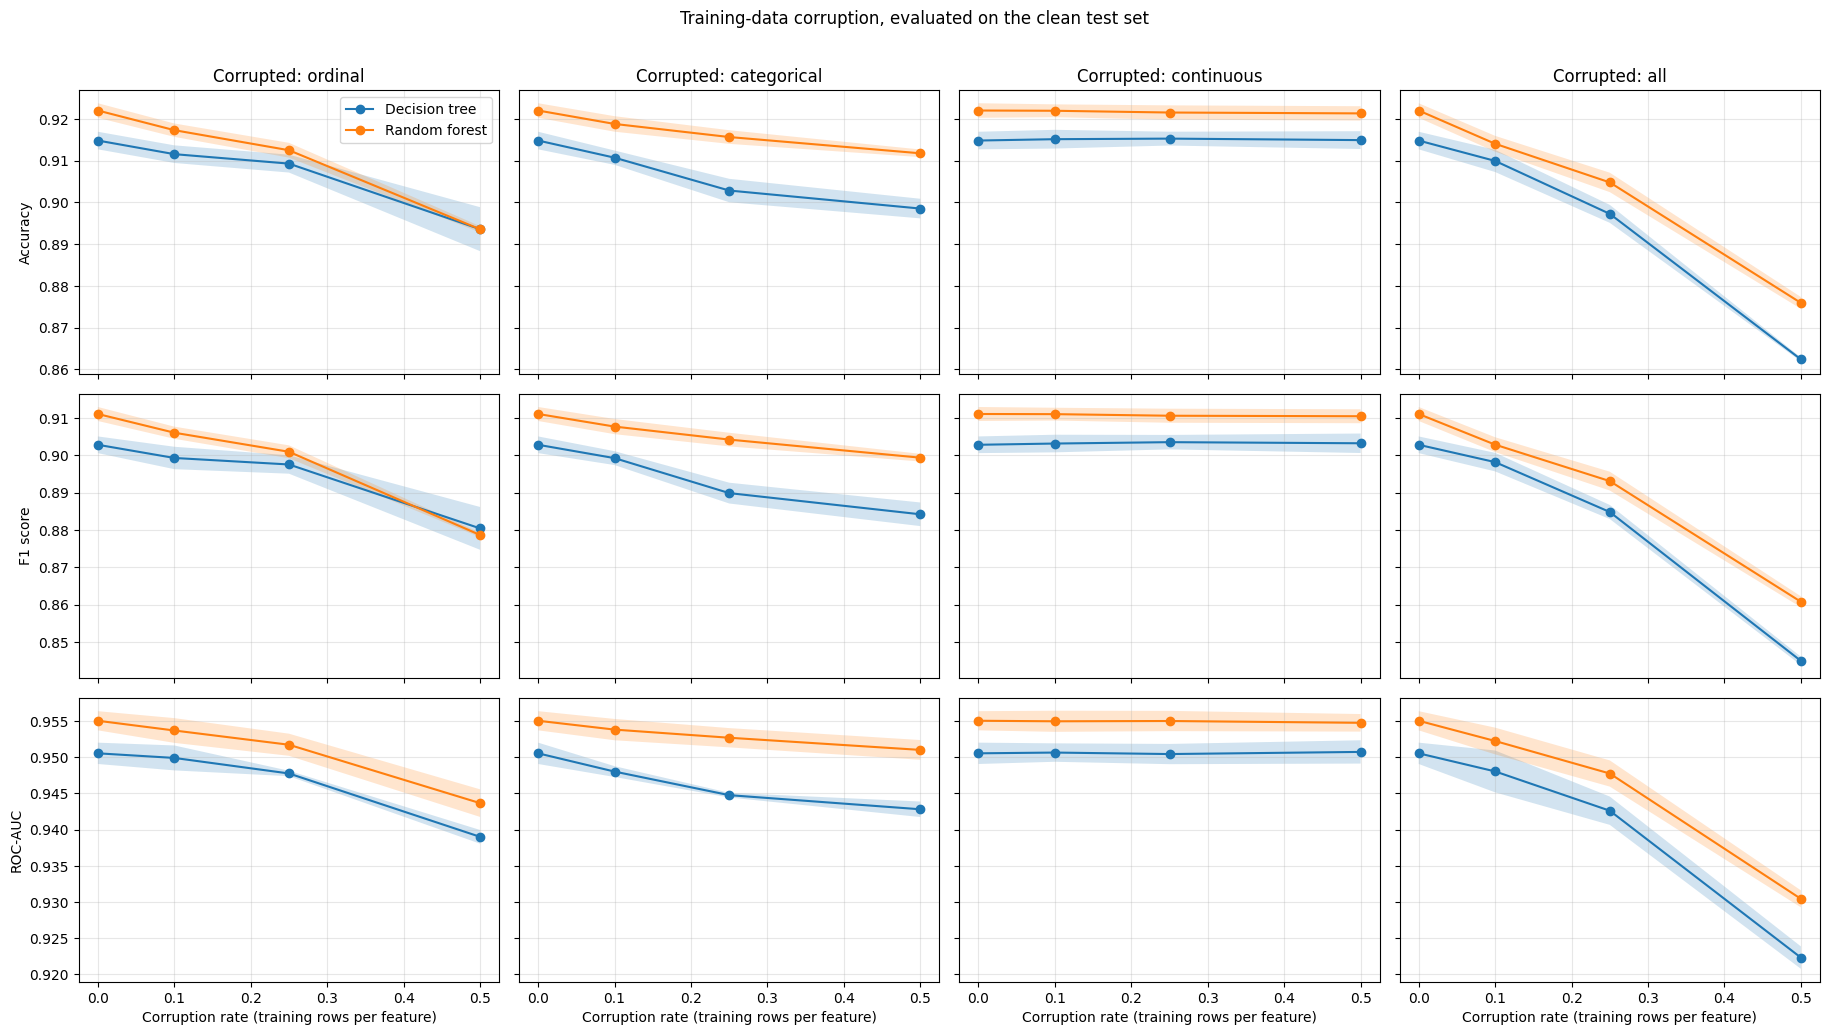

In [15]:
summary = summarize(results)

# 1) Was the nominal corruption rate really achieved? (identical for both models)
check = (
    summary[summary["model"] == exp_models[0]]
    [["scenario", "rate", "realized_rate", "rows_touched"]]
    .round(4)
)
print("Realized corruption:")
print(check.to_string(index=False))

# 2) Metrics (mean over splits)
print("\nTest metrics (mean over splits):")
cols = ["scenario", "model", "rate"] + METRICS
print(summary[cols].round(4).to_string(index=False))

# 3) Graphs
plot_results(results, scenarios, metrics=("accuracy", "f1", "roc_auc"))

+ The realized rate is the fraction of cells in the corrupted features that actually ended up different from the original values.

+ corrupt_features returns a True/False table marking which cells really changed, and the realized rate is just the mean of that table.

+ `realized = changed.to_numpy().mean()`

+ `rows_touched` - It is the fraction of rows with at least one changed cell.

+ With many features corrupted, this climbs fast. In a separate test, corrupting the 13 ordinal ratings at a rate of 0.1 changed 10% of cells in each feature

+ However, this touched about 74% of rows. A rate of 0.1 per feature is much harsher at the row level than it sounds.

## Second run with Quick == False

In [16]:
# --- Configuration ---------------------------------------------------------
QUICK = False            # True: 2 splits and a 100k-row training sample (much faster)

# Hyperparameters taken from the tuning cell above; change as needed.
exp_models = ["Decision tree", "Random forest"]
model_params = {
    "Decision tree": {"max_d": 10},                # -> found by iterating over depth it previously
    "Random forest": {"max_d": 20, "n_est": 100},  # -> minimal difference between 100-500 estimators
                                                   #    here, number has been reduced in interest of time
}

continuous_features = [c for c in numeric_features if c not in ordinal_features]
scenarios = {
    "ordinal": ordinal_features,
    "categorical": categorical_features,
    "continuous": continuous_features,
    "all": ordinal_features + categorical_features + continuous_features,
}
rates = (0.1, 0.25, 0.5, 0.65)

# --- Run -------------------------------------------------------------------
results = run_corruption_experiment(
    build_fn=build_pipeline,
    model_names=exp_models,
    X_original=X_original, y=y, splits=splits,
    scenarios=scenarios, continuous_features=continuous_features,
    rates=rates,
    n_splits=2 if QUICK else 3,
    model_params=model_params,
    train_sample=100_000 if QUICK else None,
)
results.to_csv("corruption_results.csv", index=False)

seed=   42 | clean       | rate=0.00 | realized=0.000
seed=   42 | ordinal     | rate=0.10 | realized=0.100
seed=   42 | ordinal     | rate=0.25 | realized=0.250
seed=   42 | ordinal     | rate=0.50 | realized=0.500
seed=   42 | ordinal     | rate=0.65 | realized=0.650
seed=   42 | categorical | rate=0.10 | realized=0.100
seed=   42 | categorical | rate=0.25 | realized=0.250
seed=   42 | categorical | rate=0.50 | realized=0.500
seed=   42 | categorical | rate=0.65 | realized=0.650
seed=   42 | continuous  | rate=0.10 | realized=0.076
seed=   42 | continuous  | rate=0.25 | realized=0.189
seed=   42 | continuous  | rate=0.50 | realized=0.378
seed=   42 | continuous  | rate=0.65 | realized=0.491
seed=   42 | all         | rate=0.10 | realized=0.095
seed=   42 | all         | rate=0.25 | realized=0.238
seed=   42 | all         | rate=0.50 | realized=0.477
seed=   42 | all         | rate=0.65 | realized=0.620
seed=  123 | clean       | rate=0.00 | realized=0.000
seed=  123 | ordinal     | r

Realized corruption:
   scenario  rate  realized_rate  rows_touched
        all  0.10         0.0953        0.8785
        all  0.25         0.2383        0.9967
        all  0.50         0.4767        1.0000
        all  0.65         0.6197        1.0000
categorical  0.10         0.1000        0.3438
categorical  0.25         0.2500        0.6835
categorical  0.50         0.5000        0.9375
categorical  0.65         0.6500        0.9850
      clean  0.00         0.0000        0.0000
 continuous  0.10         0.0755        0.2705
 continuous  0.25         0.1887        0.5709
 continuous  0.50         0.3776        0.8597
 continuous  0.65         0.4909        0.9434
    ordinal  0.10         0.1000        0.7461
    ordinal  0.25         0.2500        0.9761
    ordinal  0.50         0.5000        0.9999
    ordinal  0.65         0.6500        1.0000

Test metrics (mean over splits):
   scenario         model  rate  accuracy  balanced_accuracy     f1  roc_auc
        all Decision t

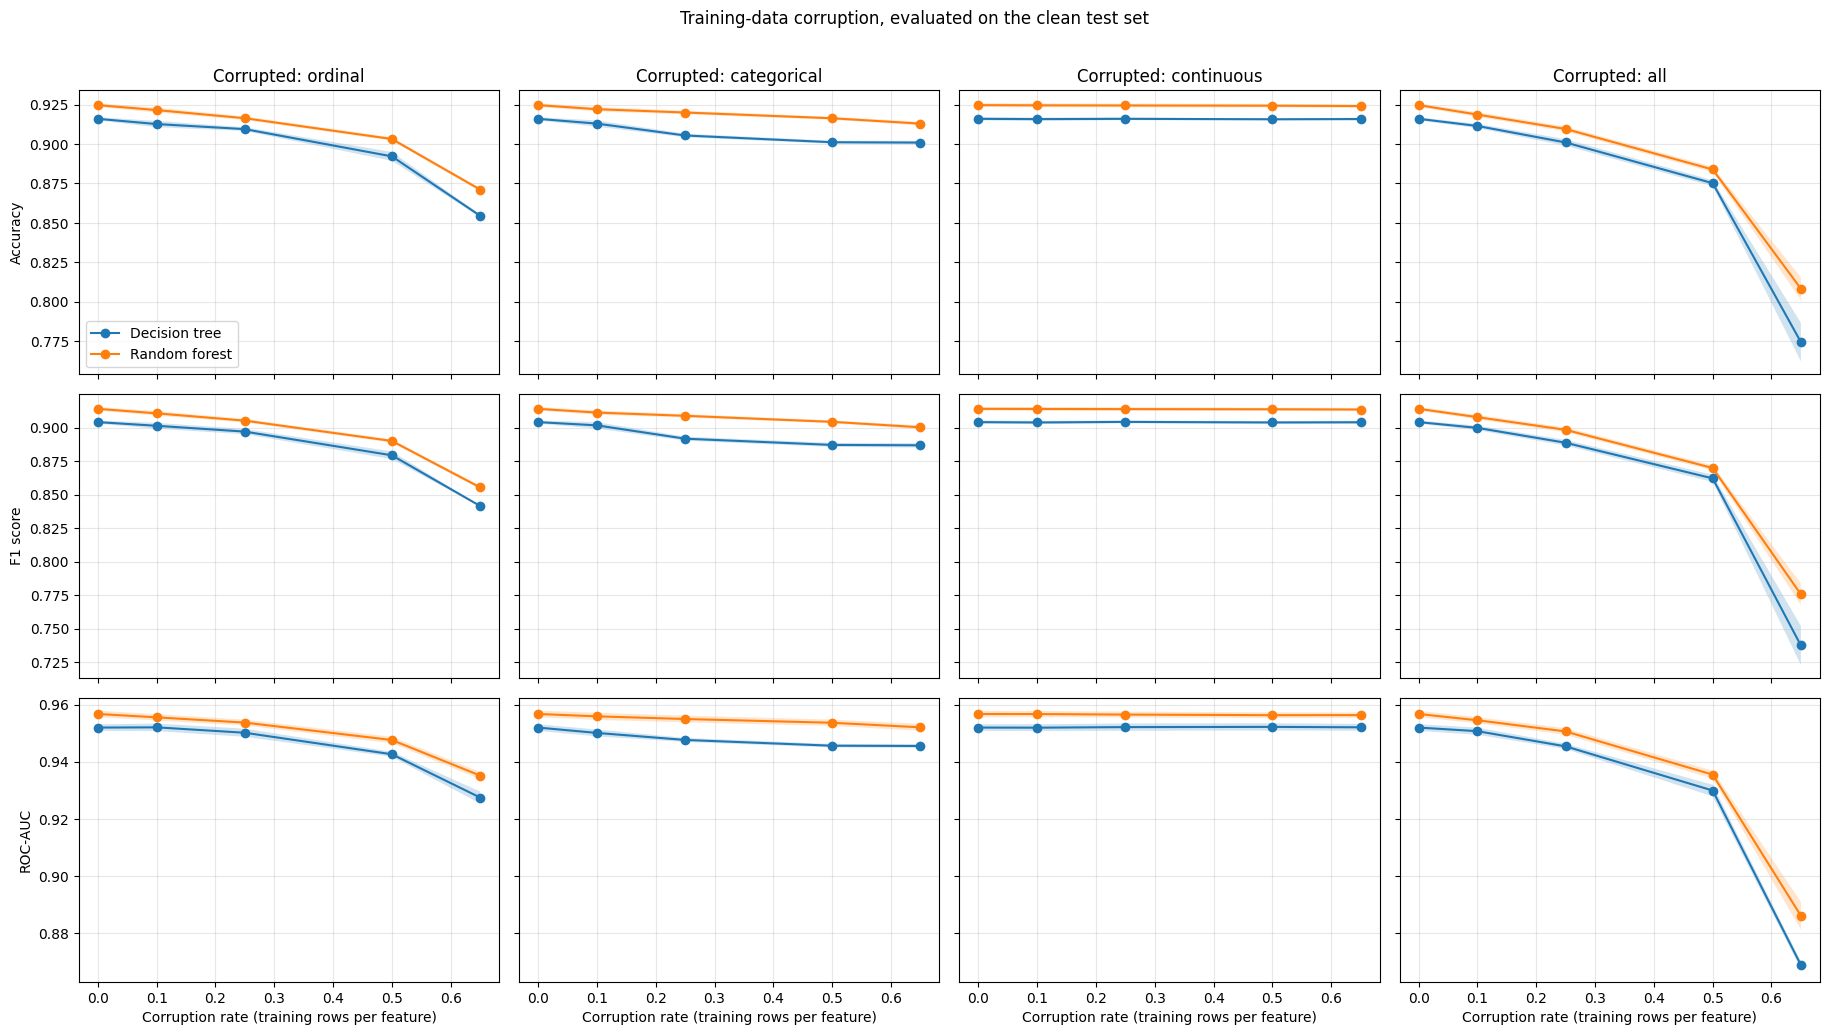

In [17]:
summary = summarize(results)

# 1) Was the nominal corruption rate really achieved? (identical for both models)
check = (
    summary[summary["model"] == exp_models[0]]
    [["scenario", "rate", "realized_rate", "rows_touched"]]
    .round(4)
)
print("Realized corruption:")
print(check.to_string(index=False))

# 2) Metrics (mean over splits)
print("\nTest metrics (mean over splits):")
cols = ["scenario", "model", "rate"] + METRICS
print(summary[cols].round(4).to_string(index=False))

# 3) Graphs
plot_results(results, scenarios, metrics=("accuracy", "f1", "roc_auc"))

## Label corruption experiment (label noise)

**Question.** How much does each model degrade when the *training labels* are wrong, while the features and the test labels stay clean?

**Protocol.** Same as the feature experiment, except the corrupted object is `y_train`. `X_train` is untouched, and the test set (`X_test`, `y_test`) is always clean. Both models are fit on the same noisy labels for each split, rate and mode.

**Noise modes.** The target is binary (0 = not satisfied, 1 = satisfied), so corrupting a label means flipping it.

| Mode | Which labels are flipped | Real-world meaning |
|---|---|---|
| `symmetric` | a fraction `p` of **all** training rows, chosen uniformly | random annotation or recording errors |
| `pos_to_neg` | a fraction `p` of the **positive** rows become 0 | satisfied passengers recorded as unsatisfied |
| `neg_to_pos` | a fraction `p` of the **negative** rows become 1 | unsatisfied passengers recorded as satisfied |

**Rate semantics.** For `symmetric`, `p` is the overall flip rate. For the two class-conditional modes, `p` is the flip rate *within the affected class*, so the overall flip rate is `p` times that class's share of the data.

**What to check.**
- `realized_rate`: the overall fraction of training labels that differ from the truth. It equals the nominal value by construction (up to rounding), but class-conditional modes make it smaller than `p`.
- `flip_rate_pos` and `flip_rate_neg`: the fraction of true positives or negatives that were flipped.
- `train_pos_share`: the share of positives after corruption. Class-conditional noise shifts this, which can move the decision threshold and hurt F1 and accuracy more than ROC-AUC.

**Limits of the rates.** Symmetric noise at `p = 0.5` makes the labels pure noise, so no model can learn anything. Keep `p < 0.5`. Class-conditional noise can also go wrong at lower rates when the flipped fraction is large relative to the class size.

In [18]:
def corrupt_labels(y, rate, seed, mode="symmetric"):
    """Flip binary labels (0/1).

    symmetric  : flip `rate` of ALL rows, chosen uniformly.
    pos_to_neg : flip `rate` of the rows with y == 1 (to 0).
    neg_to_pos : flip `rate` of the rows with y == 0 (to 1).
    Returns the corrupted labels as a Series with the same index.
    """
    rng = np.random.default_rng(seed)
    y_arr = y.to_numpy().copy()
    if mode == "symmetric":
        pool = np.arange(len(y_arr))
    elif mode == "pos_to_neg":
        pool = np.flatnonzero(y_arr == 1)
    elif mode == "neg_to_pos":
        pool = np.flatnonzero(y_arr == 0)
    else:
        raise ValueError(f"Unknown mode: {mode}")

    idx = rng.choice(pool, size=int(round(rate * len(pool))), replace=False)  # exactly this many
    y_arr[idx] = 1 - y_arr[idx]
    return pd.Series(y_arr, index=y.index, name=y.name)


def run_label_corruption_experiment(
    build_fn, model_names, X_original, y, splits,
    modes=("symmetric", "pos_to_neg", "neg_to_pos"),
    rates=(0.1, 0.2, 0.4), n_splits=3, model_params=None, train_sample=None,
):
    """Corrupt y_train only, fit each model on (clean X_train, noisy y_train),
    and score on the CLEAN test set."""
    model_params = model_params or {}
    rows = []
    for sp in splits[:n_splits]:
        X_train, y_train = X_original.loc[sp["train_idx"]], y.loc[sp["train_idx"]]
        X_test, y_test = X_original.loc[sp["test_idx"]], y.loc[sp["test_idx"]]

        if train_sample and len(X_train) > train_sample:        # optional speed-up
            X_train = X_train.sample(train_sample, random_state=sp["seed"])
            y_train = y_train.loc[X_train.index]

        jobs = [("clean", 0.0)] + [(m, r) for m in modes for r in rates]
        for mode, rate in jobs:
            if mode == "clean":
                y_noisy = y_train
            else:
                y_noisy = corrupt_labels(
                    y_train, rate, seed=[sp["seed"], int(round(rate * 1000)), modes.index(mode)],
                    mode=mode,
                )
            flipped = (y_noisy.to_numpy() != y_train.to_numpy())
            pos = (y_train.to_numpy() == 1)
            stats = {
                "realized_rate": float(flipped.mean()),
                "flip_rate_pos": float(flipped[pos].mean()),
                "flip_rate_neg": float(flipped[~pos].mean()),
                "train_pos_share": float(y_noisy.mean()),
            }
            for name in model_names:                              # same noisy labels for every model
                pipe = build_fn(name, seed=sp["seed"], **model_params.get(name, {}))
                pipe.fit(X_train, y_noisy)
                rows.append({
                    "split_seed": sp["seed"], "scenario": mode, "rate": rate,
                    "model": name, **stats, **evaluate(pipe, X_test, y_test),
                })
            print(f"seed={sp['seed']:>5} | {mode:<10} | rate={rate:.2f} | realized={stats['realized_rate']:.3f}")
    return pd.DataFrame(rows)


def summarize_labels(results):
    stat_cols = ["realized_rate", "flip_rate_pos", "flip_rate_neg", "train_pos_share"]
    g = results.groupby(["scenario", "model", "rate"])
    mean = g[stat_cols + METRICS].mean()
    std = g[METRICS].std().add_suffix("_std")
    return mean.join(std).reset_index()

## Quick == True run

In [19]:
# --- Configuration ---------------------------------------------------------
QUICK = True            # True: 2 splits and a 100k-row training sample (much faster)
# exp_models = ["Decision tree", "Random forest"]
label_modes = ["symmetric", "pos_to_neg", "neg_to_pos"]
label_rates = (0.1, 0.2, 0.4)

# --- Run (exp_models and model_params come from the feature experiment cell) ---
label_results = run_label_corruption_experiment(
    build_fn=build_pipeline,
    model_names=exp_models,
    X_original=X_original, y=y, splits=splits,
    modes=label_modes, rates=label_rates,
    n_splits=2 if QUICK else 3,
    model_params=model_params,
    train_sample=100_000 if QUICK else None,
)
label_results.to_csv("label_corruption_results.csv", index=False)

seed=   42 | clean      | rate=0.00 | realized=0.000
seed=   42 | symmetric  | rate=0.10 | realized=0.100
seed=   42 | symmetric  | rate=0.20 | realized=0.200
seed=   42 | symmetric  | rate=0.40 | realized=0.400
seed=   42 | pos_to_neg | rate=0.10 | realized=0.045
seed=   42 | pos_to_neg | rate=0.20 | realized=0.089
seed=   42 | pos_to_neg | rate=0.40 | realized=0.179
seed=   42 | neg_to_pos | rate=0.10 | realized=0.055
seed=   42 | neg_to_pos | rate=0.20 | realized=0.111
seed=   42 | neg_to_pos | rate=0.40 | realized=0.221
seed=  123 | clean      | rate=0.00 | realized=0.000
seed=  123 | symmetric  | rate=0.10 | realized=0.100
seed=  123 | symmetric  | rate=0.20 | realized=0.200
seed=  123 | symmetric  | rate=0.40 | realized=0.400
seed=  123 | pos_to_neg | rate=0.10 | realized=0.044
seed=  123 | pos_to_neg | rate=0.20 | realized=0.089
seed=  123 | pos_to_neg | rate=0.40 | realized=0.177
seed=  123 | neg_to_pos | rate=0.10 | realized=0.056
seed=  123 | neg_to_pos | rate=0.20 | realized

Realized label corruption:
  scenario  rate  realized_rate  flip_rate_pos  flip_rate_neg  train_pos_share
     clean   0.0         0.0000         0.0000         0.0000           0.4449
neg_to_pos   0.1         0.0555         0.0000         0.1000           0.5004
neg_to_pos   0.2         0.1110         0.0000         0.2000           0.5559
neg_to_pos   0.4         0.2220         0.0000         0.4000           0.6670
pos_to_neg   0.1         0.0445         0.1000         0.0000           0.4004
pos_to_neg   0.2         0.0890         0.2000         0.0000           0.3559
pos_to_neg   0.4         0.1780         0.4000         0.0000           0.2670
 symmetric   0.1         0.1000         0.0989         0.1009           0.4569
 symmetric   0.2         0.2000         0.1999         0.2001           0.4670
 symmetric   0.4         0.4000         0.4019         0.3985           0.4873

Test metrics (mean over splits):
  scenario         model  rate  accuracy  balanced_accuracy     f1  ro

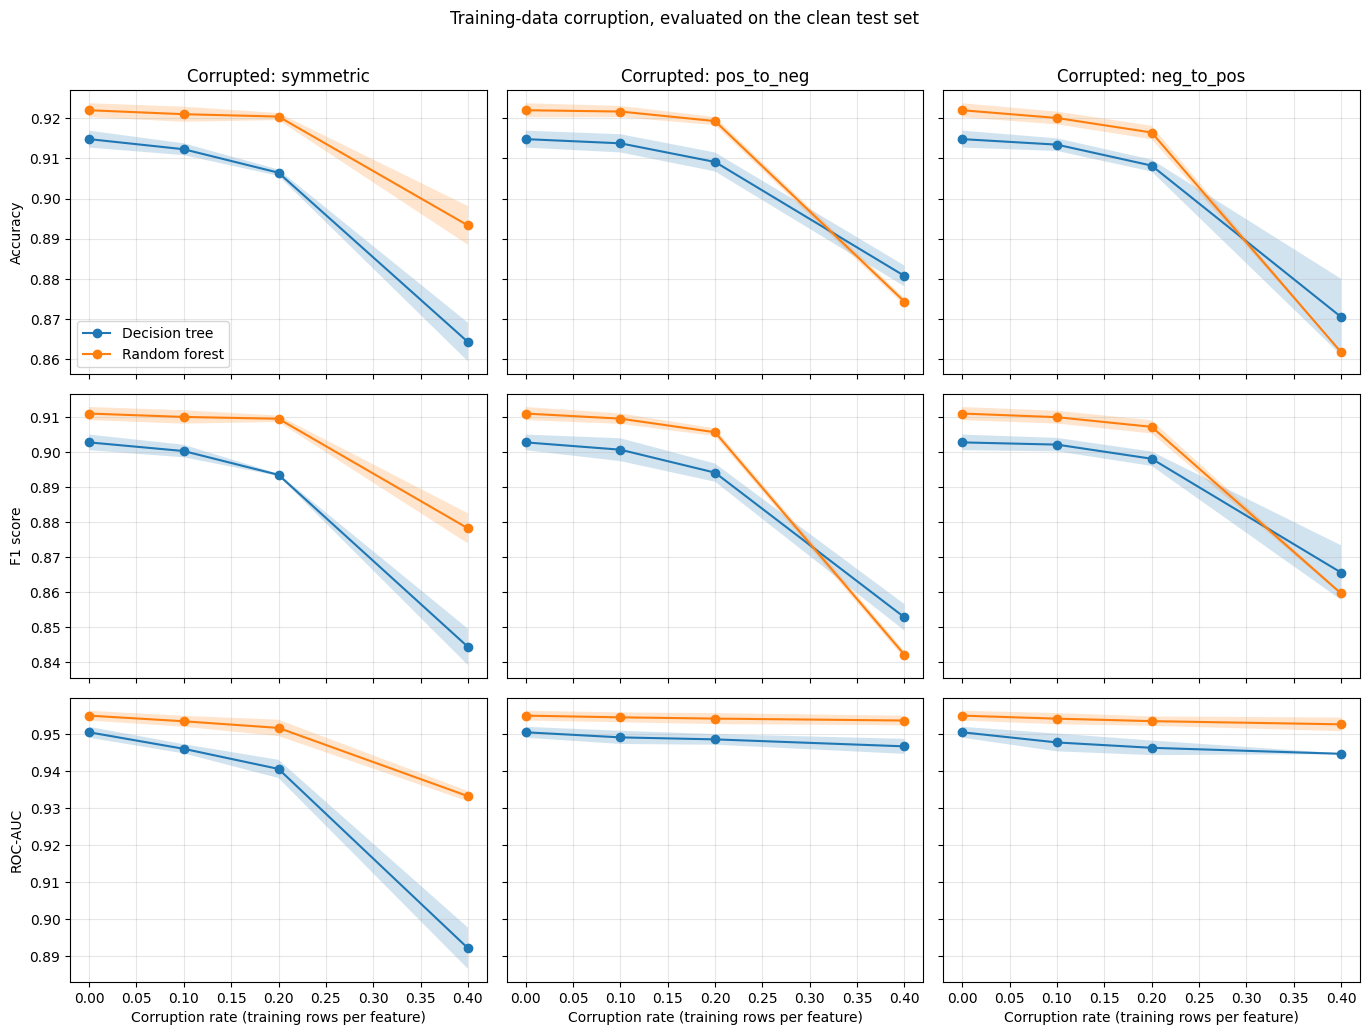

In [20]:
label_summary = summarize_labels(label_results)

# 1) Was the nominal flip rate achieved? (identical for both models)
check = (
    label_summary[label_summary["model"] == exp_models[0]]
    [["scenario", "rate", "realized_rate", "flip_rate_pos", "flip_rate_neg", "train_pos_share"]]
    .round(4)
)
print("Realized label corruption:")
print(check.to_string(index=False))

# 2) Metrics (mean over splits)
print("\nTest metrics (mean over splits):")
print(label_summary[["scenario", "model", "rate"] + METRICS].round(4).to_string(index=False))

# 3) Graphs
plot_results(
    label_results, label_modes, metrics=("accuracy", "f1", "roc_auc"),
    savepath="label_corruption_results.png",
)

## Quick == False run

In [21]:
# --- Configuration ---------------------------------------------------------
QUICK = False            # True: 2 splits and a 100k-row training sample (much faster)
# exp_models = ["Decision tree", "Random forest"]
label_modes = ["symmetric", "pos_to_neg", "neg_to_pos"]
label_rates = (0.1, 0.2, 0.4)

# --- Run (exp_models and model_params come from the feature experiment cell) ---
label_results = run_label_corruption_experiment(
    build_fn=build_pipeline,
    model_names=exp_models,
    X_original=X_original, y=y, splits=splits,
    modes=label_modes, rates=label_rates,
    n_splits=2 if QUICK else 3,
    model_params=model_params,
    train_sample=100_000 if QUICK else None,
)
label_results.to_csv("label_corruption_results.csv", index=False)

seed=   42 | clean      | rate=0.00 | realized=0.000
seed=   42 | symmetric  | rate=0.10 | realized=0.100
seed=   42 | symmetric  | rate=0.20 | realized=0.200
seed=   42 | symmetric  | rate=0.40 | realized=0.400
seed=   42 | pos_to_neg | rate=0.10 | realized=0.044
seed=   42 | pos_to_neg | rate=0.20 | realized=0.089
seed=   42 | pos_to_neg | rate=0.40 | realized=0.177
seed=   42 | neg_to_pos | rate=0.10 | realized=0.056
seed=   42 | neg_to_pos | rate=0.20 | realized=0.111
seed=   42 | neg_to_pos | rate=0.40 | realized=0.223
seed=  123 | clean      | rate=0.00 | realized=0.000
seed=  123 | symmetric  | rate=0.10 | realized=0.100
seed=  123 | symmetric  | rate=0.20 | realized=0.200
seed=  123 | symmetric  | rate=0.40 | realized=0.400
seed=  123 | pos_to_neg | rate=0.10 | realized=0.044
seed=  123 | pos_to_neg | rate=0.20 | realized=0.089
seed=  123 | pos_to_neg | rate=0.40 | realized=0.177
seed=  123 | neg_to_pos | rate=0.10 | realized=0.056
seed=  123 | neg_to_pos | rate=0.20 | realized

Realized label corruption:
  scenario  rate  realized_rate  flip_rate_pos  flip_rate_neg  train_pos_share
     clean   0.0         0.0000         0.0000         0.0000           0.4436
neg_to_pos   0.1         0.0556         0.0000         0.1000           0.4992
neg_to_pos   0.2         0.1113         0.0000         0.2000           0.5549
neg_to_pos   0.4         0.2226         0.0000         0.4000           0.6661
pos_to_neg   0.1         0.0444         0.1000         0.0000           0.3992
pos_to_neg   0.2         0.0887         0.2000         0.0000           0.3549
pos_to_neg   0.4         0.1774         0.4000         0.0000           0.2661
 symmetric   0.1         0.1000         0.1000         0.1000           0.4548
 symmetric   0.2         0.2000         0.1992         0.2006           0.4668
 symmetric   0.4         0.4000         0.3999         0.4001           0.4888

Test metrics (mean over splits):
  scenario         model  rate  accuracy  balanced_accuracy     f1  ro

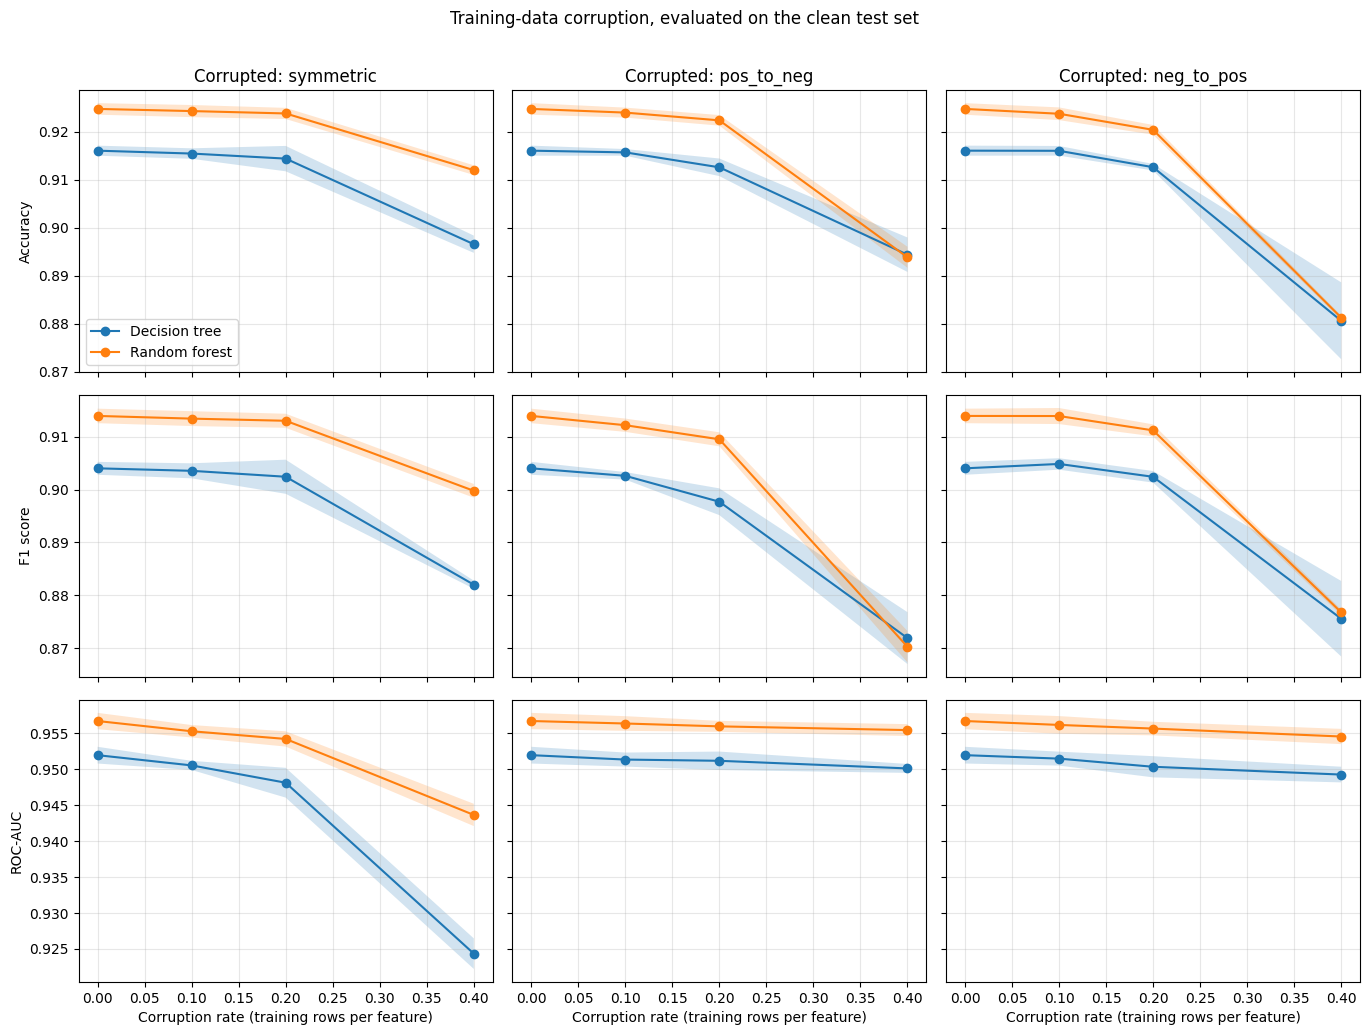

In [22]:
label_summary = summarize_labels(label_results)

# 1) Was the nominal flip rate achieved? (identical for both models)
check = (
    label_summary[label_summary["model"] == exp_models[0]]
    [["scenario", "rate", "realized_rate", "flip_rate_pos", "flip_rate_neg", "train_pos_share"]]
    .round(4)
)
print("Realized label corruption:")
print(check.to_string(index=False))

# 2) Metrics (mean over splits)
print("\nTest metrics (mean over splits):")
print(label_summary[["scenario", "model", "rate"] + METRICS].round(4).to_string(index=False))

# 3) Graphs
plot_results(
    label_results, label_modes, metrics=("accuracy", "f1", "roc_auc"),
    savepath="label_corruption_results.png",
)